In [4]:
#!pip install tensorflow
#!pip install matplotlib
#!pip install scikit-learn
#!pip install tqdm


## JUST FOR CUDA USERS:
#from tensorflow.keras import backend as K
import tensorflow as tf
#K.clear_session()
#tf.compat.v1.reset_default_graph()
tf.config.set_visible_devices([], 'GPU')

## APRENDIZAJE FEDERADO.

El aprendizaje federado consiste en entrenar un modelo localmente con un subconjunto de datos, para después computar un modelo global (idéntico) que será desplegado como un servicio.

Para simular una situación de aprendizaje federado, usaremos la bien-conocida base de datos MNIST para interpretar número escritos a mano, y la dividiremos en cinco partes (en su caso, será en cuantos miembros de su equipo tengan).

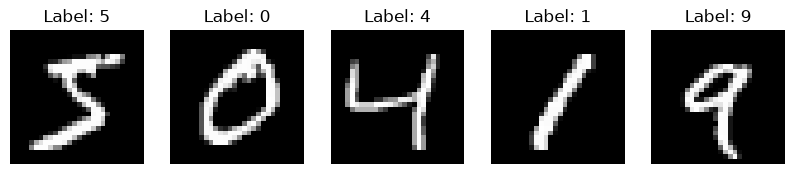

15000
Frecuencia de números: {0: 1480, 1: 1685, 2: 1489, 3: 1533, 4: 1461, 5: 1356, 6: 1479, 7: 1567, 8: 1462, 9: 1488}
Primeros ejemplos (labels): [5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1]
15000
Frecuencia de números: {0: 1481, 1: 1685, 2: 1490, 3: 1533, 4: 1461, 5: 1355, 6: 1479, 7: 1566, 8: 1463, 9: 1487}
Primeros ejemplos (labels): [7, 7, 0, 7, 7, 7, 3, 3, 7, 0, 0, 3, 7, 3, 7]
15000
Frecuencia de números: {0: 1481, 1: 1686, 2: 1490, 3: 1532, 4: 1460, 5: 1355, 6: 1480, 7: 1566, 8: 1463, 9: 1487}
Primeros ejemplos (labels): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
15000
Frecuencia de números: {0: 1481, 1: 1686, 2: 1489, 3: 1533, 4: 1460, 5: 1355, 6: 1480, 7: 1566, 8: 1463, 9: 1487}
Primeros ejemplos (labels): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 9, 9]


In [5]:
import tensorflow as tf
import numpy as np

train, test = tf.keras.datasets.mnist.load_data()

x_train, x_test = np.expand_dims(train[0] / 255.0, -1), np.expand_dims(test[0] / 255.0, -1)
y_train, y_test = train[1], test[1]

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()


## Data split para simular cinco datos aparte.
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=4)

folds = skf.split(x_train, y_train)

local_data = [(x_train[tsix], y_train[tsix]) for trix, tsix in folds]

for x in local_data:
    print(len(x[0]))
    print(f"Frecuencia de números: { {int(y):list(x[1]).count(y) for y in set(x[1])} }")
    print(f"Primeros ejemplos (labels): {[int(y) for y in list(x[1])[:15]]}")

Same seed initialization (p.4):
https://proceedings.mlr.press/v54/mcmahan17a/mcmahan17a.pdf

A same seed initialization was used, as when each individual client parts from a random step, the follow up models perrform poorly in contrast when initializing them into the same seed/ initial weight

FOLD (array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[

DEBUGGG
<Functional name=functional_5, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8647 - loss: 0.4909 - val_accuracy: 0.9204 - val_loss: 0.2706
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 847us/step - accuracy: 0.9345 - loss: 0.2278 - val_accuracy: 0.9411 - val_loss: 0.1963
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 777us/step - accuracy: 0.9528 - loss: 0.1646 - val_accuracy: 0.9468 - val_loss: 0.1771
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 760us/step - accuracy: 0.9617 - loss: 0.1286 - val_accuracy: 0.9419 - val_loss: 0.1883
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step - accuracy: 0.9716 - loss: 0.1001 - val_accuracy: 0.9537 - val_loss: 0.1634
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 885us/step - accuracy: 0.9757 - loss: 0.0810 - val_accuracy: 0.9538 - val_loss: 0.1564
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 901us/step - accuracy: 0.9809 - loss: 0.0658 - val_accuracy: 0.9576 - val_loss: 0.1512
Epoch 8/15
46

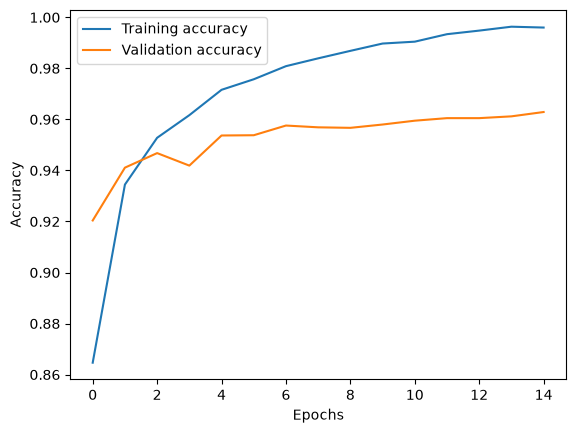

FOLD (array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[

DEBUGGG
<Functional name=functional_6, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 984us/step - accuracy: 0.8609 - loss: 0.4865 - val_accuracy: 0.9186 - val_loss: 0.2744
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9321 - loss: 0.2255 - val_accuracy: 0.9401 - val_loss: 0.2007
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 867us/step - accuracy: 0.9472 - loss: 0.1708 - val_accuracy: 0.9476 - val_loss: 0.1710
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 936us/step - accuracy: 0.9585 - loss: 0.1318 - val_accuracy: 0.9458 - val_loss: 0.1762
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 799us/step - accuracy: 0.9694 - loss: 0.1035 - val_accuracy: 0.9490 - val_loss: 0.1741
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 807us/step - accuracy: 0.9733 - loss: 0.0866 - val_accuracy: 0.9514 - val_loss: 0.1684
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 770us/step - accuracy: 0.9771 - loss: 0.0717 - val_accuracy: 0.9507 - val_loss: 0.1740
Epoch 8/15
46

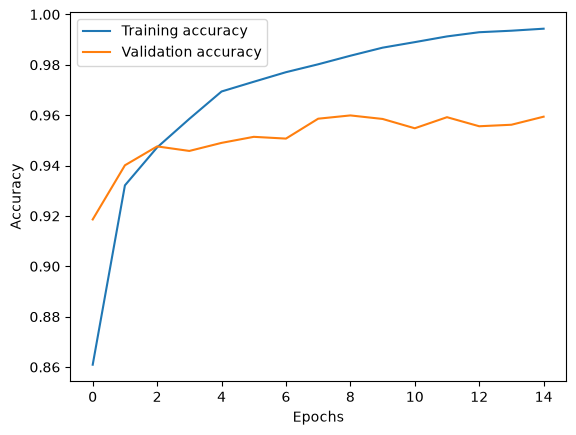

FOLD (array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[

DEBUGGG
<Functional name=functional_7, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8523 - loss: 0.5076 - val_accuracy: 0.9179 - val_loss: 0.2752
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9305 - loss: 0.2350 - val_accuracy: 0.9339 - val_loss: 0.2164
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 851us/step - accuracy: 0.9477 - loss: 0.1735 - val_accuracy: 0.9482 - val_loss: 0.1791
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 891us/step - accuracy: 0.9608 - loss: 0.1382 - val_accuracy: 0.9487 - val_loss: 0.1787
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 826us/step - accuracy: 0.9682 - loss: 0.1095 - val_accuracy: 0.9477 - val_loss: 0.1809
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9734 - loss: 0.0906 - val_accuracy: 0.9557 - val_loss: 0.1588
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step - accuracy: 0.9773 - loss: 0.0754 - val_accuracy: 0.9566 - val_loss: 0.1472
Epoch 8/15
469/46

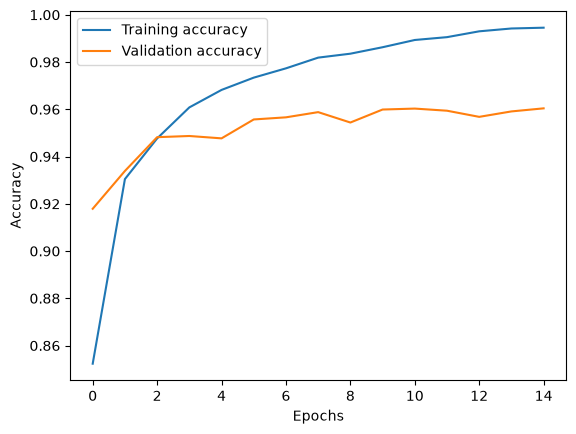

FOLD (array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[

DEBUGGG
<Functional name=functional_8, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8663 - loss: 0.4673 - val_accuracy: 0.9047 - val_loss: 0.3071
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9314 - loss: 0.2281 - val_accuracy: 0.9370 - val_loss: 0.2060
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 790us/step - accuracy: 0.9495 - loss: 0.1670 - val_accuracy: 0.9447 - val_loss: 0.1806
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 834us/step - accuracy: 0.9597 - loss: 0.1321 - val_accuracy: 0.9468 - val_loss: 0.1766
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 909us/step - accuracy: 0.9673 - loss: 0.1043 - val_accuracy: 0.9519 - val_loss: 0.1631
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 843us/step - accuracy: 0.9733 - loss: 0.0849 - val_accuracy: 0.9536 - val_loss: 0.1599
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9782 - loss: 0.0681 - val_accuracy: 0.9565 - val_loss: 0.1569
Epoch 8/15
469/46

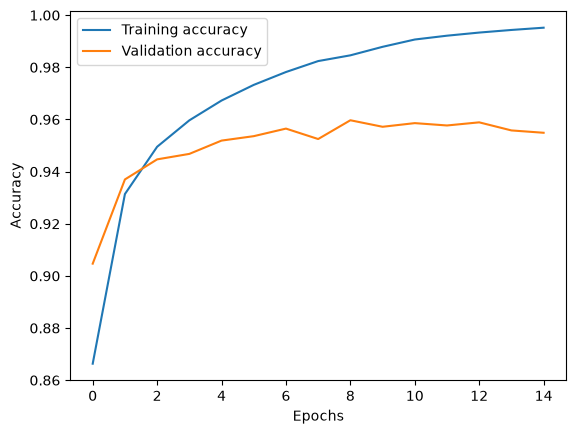

FOLD (array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[

In [6]:
from sklearn.metrics import classification_report
def train_and_verify(local_model, local_data, epochs, x_test, y_test, save_name):

    print("DEBUGGG")
    print(local_model)
    print(local_data[0].shape)
    print(local_data[1].shape)
    
    history = local_model.fit(local_data[0], local_data[1], epochs=epochs, validation_data=(x_test, y_test))
    y_pred = local_model.predict(x_test)
    y_pred_classes = np.argmax(y_pred, axis=1)
    print(classification_report(y_test, y_pred_classes))

    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

    local_model.save(save_name)

from model_2 import build
from tqdm import tqdm
# Set mismas weights iniciales
global_model = build.build_model()
initial_weights = global_model.get_weights()

# Entrenamientos locales. Cada uno de estos deben hacerse en computadoras aparte.

for x in tqdm(range(len(local_data)), desc=f"FOLD {x}"):
    local_model = build.build_model()
    local_model.set_weights(initial_weights)
    train_and_verify(local_model, local_data[x], 15, x_test, y_test, f"lmodel_{x}.keras")

In [7]:
local_model = build.build_model()

print("INPUT:", local_model.input_shape)
print("OUTPUT:", local_model.output_shape)

local_model.summary()

INPUT: (None, 28, 28, 1)
OUTPUT: (None, 10)


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
## Abrir los modelos:

import os
loaded_local_models = [tf.keras.models.load_model(os.path.join(root, file)) for root, dirs, files in os.walk("./") for file in files if file.endswith('.keras')]

for i in range(len(loaded_local_models)-1):
    assert loaded_local_models[i].summary() == loaded_local_models[i+1].summary(), "Models have different architectures"

/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_sprop_2', because it has 8 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_sprop_5', because it has 8 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_sprop_1', because it has 8 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_spro

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,102 (430.09 KB)

 Trainable params: 55,050 (215.04 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,102 (430.09 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 55,052 (215.05 KB)

## Debug

In [9]:
local_weights = [x.get_weights() for x in loaded_local_models]
averaged_weights = [np.mean(np.array(weights), axis=0) for weights in zip(*local_weights)]

global_model = build.build_model()
global_model.set_weights(averaged_weights)

from sklearn.metrics import classification_report
# Predict the classes for the test set
y_pred = global_model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

global_model.save('global_model.keras')

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 477us/step
              precision    recall  f1-score   support

           0       0.99      0.75      0.85       980
           1       0.98      0.93      0.95      1135
           2       0.93      0.86      0.90      1032
           3       1.00      0.57      0.73      1010
           4       0.91      0.81      0.86       982
           5       0.43      0.99      0.60       892
           6       0.95      0.70      0.81       958
           7       0.91      0.93      0.92      1028
           8       0.75      0.87      0.80       974
           9       0.94      0.77      0.84      1009

    accuracy                           0.82     10000
   macro avg       0.88      0.82      0.83     10000
weighted avg       0.88      0.82      0.83     10000



Epoch 1/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 867us/step - accuracy: 0.9183 - loss: 0.2797 - val_accuracy: 0.9524 - val_loss: 0.1551
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 558us/step - accuracy: 0.9606 - loss: 0.1323 - val_accuracy: 0.9671 - val_loss: 0.1114
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 543us/step - accuracy: 0.9711 - loss: 0.0968 - val_accuracy: 0.9706 - val_loss: 0.1058
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 631us/step - accuracy: 0.9757 - loss: 0.0818 - val_accuracy: 0.9732 - val_loss: 0.0990
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 624us/step - accuracy: 0.9793 - loss: 0.0685 - val_accuracy: 0.9730 - val_loss: 0.0999
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 574us/step - accuracy: 0.9825 - loss: 0.0601 - val_accuracy: 0.9746 - val_loss: 0.1017
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 546us/step - accuracy: 0.9844 - loss: 0.0531 - val_accuracy: 0.9741 - val_loss: 0.1066
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 528us/step - accuracy: 0.9865 -

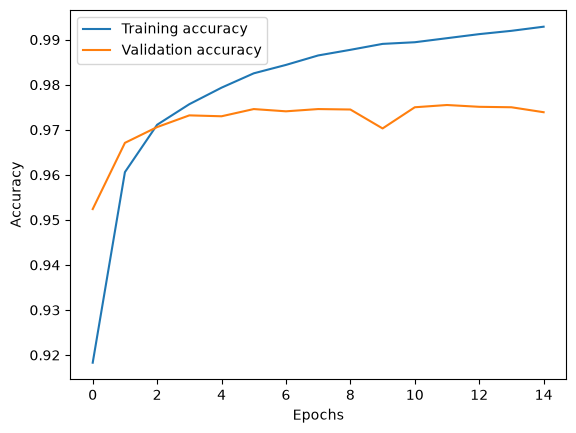

In [10]:
## VS A NORMAL GLOBLA MODEL TRAINED IN A SINGLE DEVICE:

model = build.build_model()

history = model.fit(x_train, y_train, epochs=15, validation_data=(x_test, y_test))

from sklearn.metrics import classification_report
# Predict the classes for the test set
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

# Optionally, plot training history
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Bibliography:

https://www.tensorflow.org/guide/keras/training_with_built_in_methods
